Analyze time-series data from platereader experiments.

## EsaR Template Competition

In [1]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk==0.6.2 -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [2]:

import pandas as pd
pd.set_option('display.max_columns', None)
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.instruments import platereader as pr

from cdk import logging
log = logging.setup_logging(logging.ERROR)

## Load Data

In [3]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Writing drive_utils.py


In [4]:
# Set use_drive = True to download data_file and platemap_file from Google Drive instead of
# using local files. Each Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/1IAiFH6N9sMag7jcdwwvWGr_mTqOz8mAZ/view?usp=share_link",  # Replace with your data file link.
            "filename": "raw_data.txt",
        },
        {
            "url": "https://drive.google.com/file/d/1RrYeBHgGtMEkSOTjsFj5hGUZhyayg7aJ/view?usp=share_link",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    data_file = downloaded_paths["raw_data.txt"]
    platemap_file = downloaded_paths["platemap.csv"]
else:
    data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
    platemap_file = "sample-data/platemap.csv"

print(f"Data file: {data_file}\nPlatemap file: {platemap_file}")

Data file: data/raw_data.txt
Platemap file: data/platemap.csv


In [5]:
# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [6]:
print(result)

PlateReaderResult with the following 2 blocks:
0: (876, 40) kinetic read with reads: GFP-G70:485,528 (Fluorescence) (Plate 'Plate 1')
1: (876, 40) kinetic read with reads: GFP-Gext:485,528 (Fluorescence) (Plate 'Plate 1')


Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [7]:
desired_index = 0
data = result[desired_index]

You can see the underlying data with `data.view()` (which returns a Pandas DataFrame):

In [8]:
data.view().head()

,Date,Experiment,Well,Name,Type,Time,Data,Read,Read Name,Reader Type,Reader ID,Plate Type,Plate ID,Start Time,Read Modality,Gain,Excitation Wavelength (nm),Excitation Bandwidth (nm),Excitation Optics,Emission Wavelength (nm),Emission Bandwidth (nm),Emission Optics,Read Geometry,Read Height (mm),[EsaO-mNG] (nM),[EsaR] (nM),[AHSL] (uM)
0,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,A1,EsaO-mNG (0.1 nM) + AHSL,Sample,0 days 00:00:00,49,"GFP-G70:485,528",GFP-G70,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-10-07 17:06:53,Fluorescence,70,485,20,monochromator,528,20,monochromator,Top,10.5 mm,0.1,0,0
1,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,A1,EsaO-mNG (0.1 nM) + AHSL,Sample,0 days 00:05:00,39,"GFP-G70:485,528",GFP-G70,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-10-07 17:06:53,Fluorescence,70,485,20,monochromator,528,20,monochromator,Top,10.5 mm,0.1,0,0
2,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,A1,EsaO-mNG (0.1 nM) + AHSL,Sample,0 days 00:10:00,29,"GFP-G70:485,528",GFP-G70,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-10-07 17:06:53,Fluorescence,70,485,20,monochromator,528,20,monochromator,Top,10.5 mm,0.1,0,0
3,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,A1,EsaO-mNG (0.1 nM) + AHSL,Sample,0 days 00:15:00,63,"GFP-G70:485,528",GFP-G70,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-10-07 17:06:53,Fluorescence,70,485,20,monochromator,528,20,monochromator,Top,10.5 mm,0.1,0,0
4,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,A1,EsaO-mNG (0.1 nM) + AHSL,Sample,0 days 00:20:00,91,"GFP-G70:485,528",GFP-G70,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-10-07 17:06:53,Fluorescence,70,485,20,monochromator,528,20,monochromator,Top,10.5 mm,0.1,0,0


## Plot Raw Curves

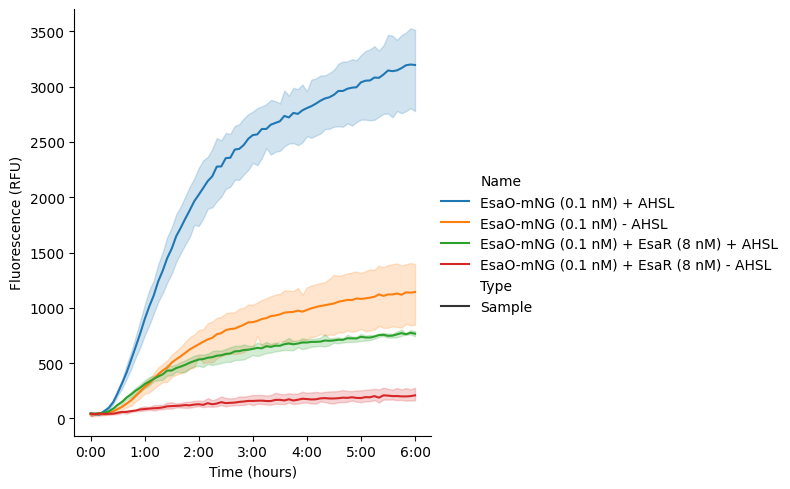

In [ ]:
data.plot(style='Type')

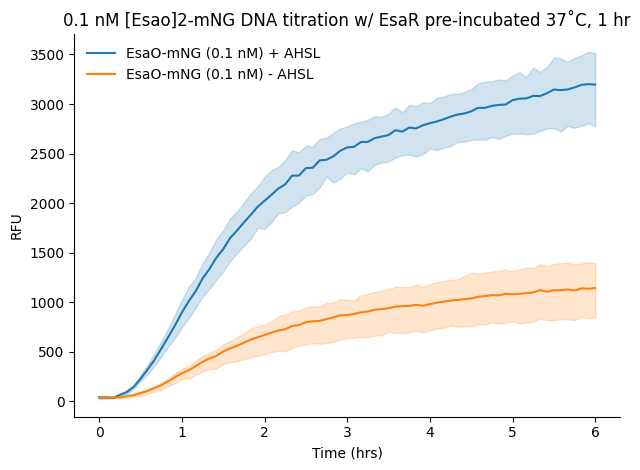

In [ ]:
data_01nM = data.select(name=["EsaO-mNG (0.1 nM) - AHSL", "EsaO-mNG (0.1 nM) + AHSL"])


df_01nM = data_01nM.data


df_01nM['Time_hrs'] = df_01nM['Time'].dt.total_seconds() / 3600

sns.lineplot(df_01nM, x="Time_hrs", y='Data', hue="Name")

plt.xlabel("Time (hrs)")
plt.ylabel("RFU")

plt.title("0.1 nM [Esao]2-mNG DNA titration w/ EsaR pre-incubated 37˚C, 1 hr")

plt.legend(frameon=False)


sns.despine()
plt.tight_layout()
plt.show()

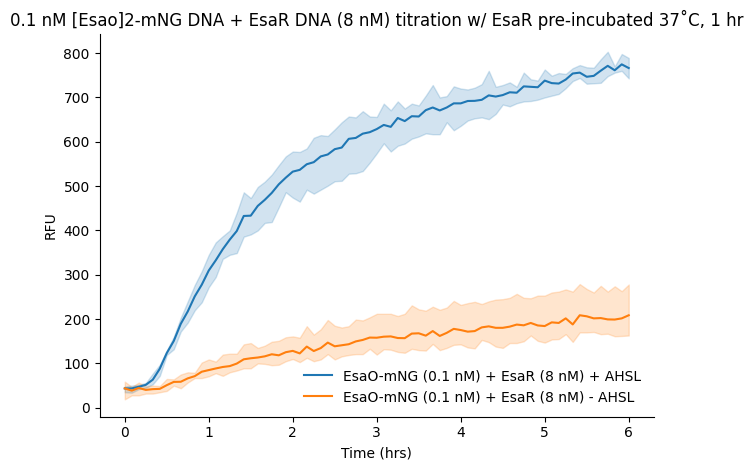

In [ ]:
data_01nM_EsaR = data.select(name=["EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL", "EsaO-mNG (0.1 nM) + EsaR (8 nM) - AHSL"])


df_01nM_EsaR = data_01nM_EsaR.data


df_01nM_EsaR['Time_hrs'] = df_01nM_EsaR['Time'].dt.total_seconds() / 3600

sns.lineplot(df_01nM_EsaR, x="Time_hrs", y='Data', hue="Name")

plt.xlabel("Time (hrs)")
plt.ylabel("RFU")

plt.title("0.1 nM [Esao]2-mNG DNA + EsaR DNA (8 nM) titration w/ EsaR pre-incubated 37˚C, 1 hr")

plt.legend(frameon=False)


sns.despine()
plt.tight_layout()
plt.show()

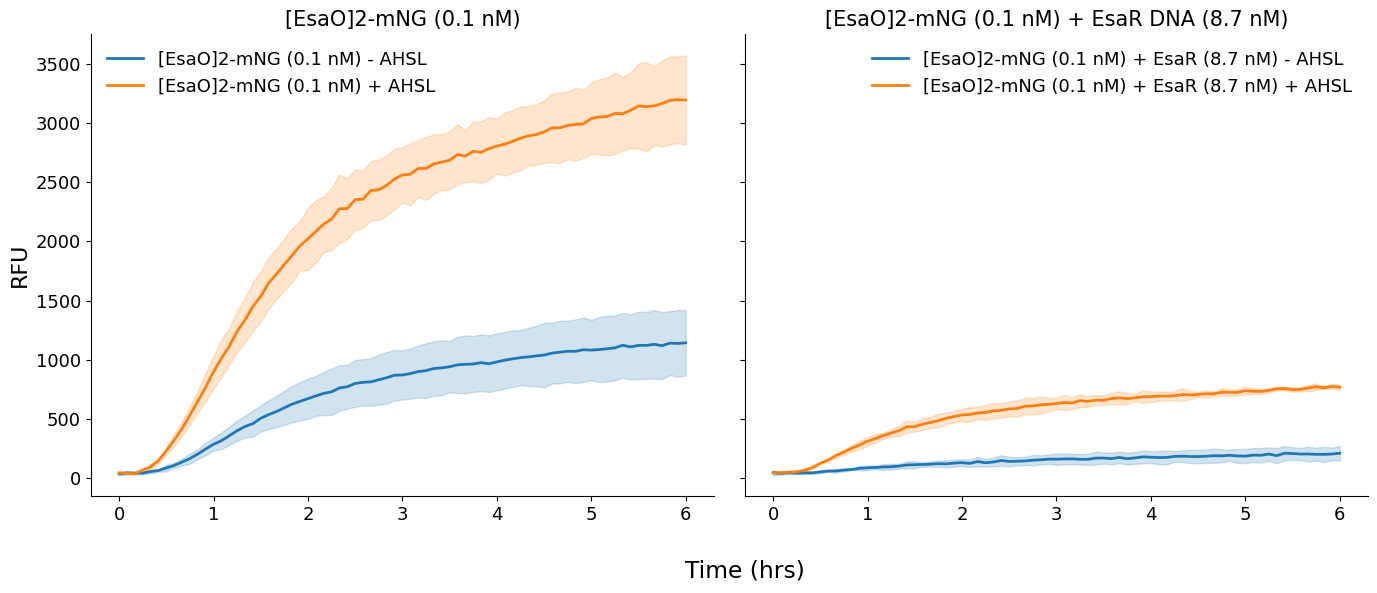

In [10]:
#| label: mbcn-20261007-fig1

plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "lines.linewidth": 2,
})

data_01nM = data.select(name=["EsaO-mNG (0.1 nM) - AHSL", "EsaO-mNG (0.1 nM) + AHSL"])
data_01nM_EsaR = data.select(name=["EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL", "EsaO-mNG (0.1 nM) + EsaR (8 nM) - AHSL"])

df_01nM = data_01nM.data
df_01nM_EsaR = data_01nM_EsaR.data

df_01nM['Time_hrs'] = df_01nM['Time'].dt.total_seconds() / 3600
df_01nM_EsaR['Time_hrs'] = df_01nM_EsaR['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# --- Left: no EsaR ---
label_map = {
    "EsaO-mNG (0.1 nM) - AHSL": "[EsaO]2-mNG (0.1 nM) - AHSL",
    "EsaO-mNG (0.1 nM) + AHSL": "[EsaO]2-mNG (0.1 nM) + AHSL",
}

df_01nM['Label'] = df_01nM['Name'].replace(label_map)

sns.lineplot(df_01nM, x="Time_hrs", y='Data', hue="Label", ax=ax1,
             hue_order=["[EsaO]2-mNG (0.1 nM) - AHSL", "[EsaO]2-mNG (0.1 nM) + AHSL"], errorbar='sd')
ax1.set_title("[EsaO]2-mNG (0.1 nM)")
ax1.set(xlabel="", ylabel="RFU")
ax1.legend(frameon=False)

# --- Right: + EsaR ---
label_map_EsaR = {
    "EsaO-mNG (0.1 nM) + EsaR (8 nM) - AHSL": "[EsaO]2-mNG (0.1 nM) + EsaR (8.7 nM) - AHSL",
    "EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL": "[EsaO]2-mNG (0.1 nM) + EsaR (8.7 nM) + AHSL",
}
df_01nM_EsaR['Label'] = df_01nM_EsaR['Name'].replace(label_map_EsaR)

sns.lineplot(df_01nM_EsaR, x="Time_hrs", y='Data', hue="Label", ax=ax2,
             hue_order=["[EsaO]2-mNG (0.1 nM) + EsaR (8.7 nM) - AHSL", "[EsaO]2-mNG (0.1 nM) + EsaR (8.7 nM) + AHSL"], errorbar='sd')
ax2.set_title("[EsaO]2-mNG (0.1 nM) + EsaR DNA (8.7 nM)")
ax2.set(xlabel="", ylabel="")
ax2.legend(frameon=False)

sns.despine()
fig.supxlabel("Time (hrs)", x=0.54)
plt.tight_layout()
plt.show()

In [ ]:
df_01nM_EsaR.head()

,Time,Temperature,Well,Data,Read,Read Name,Read Modality,Read Geometry,Emission Optics,Excitation Optics,Excitation Wavelength (nm),Excitation Bandwidth (nm),Emission Wavelength (nm),Emission Bandwidth (nm),Filter Set,Gain,Read Range,Light Source,Lamp Energy,Dynamic Range,Read Speed,Delay,Measurements/Data Point,Read Height (mm),Software Version,Experiment File Path,Protocol File Path,Plate ID,Reader Type,Reader ID,Reading Type,Start Time,Plate Type,Date,Experiment,Name,Type,[EsaO-mNG] (nM),[EsaR] (nM),[AHSL] (uM),Time_hrs
0,0 days 00:00:00,37.10,A5,48,"GFP-G70:485,528",GFP-G70,Fluorescence,Top,monochromator,monochromator,485,20,528,20,Filter Set 1,70,Full Plate,Xenon Flash,High,Standard,Normal,100 msec,10,10.5 mm,3.16.10,C:\Users\bnext\Documents\Biotek\experiments\20...,C:\Users\bnext\Documents\Biotek\protocols\cyta...,Plate 1,Cytation5,1705168,Reader,2026-10-07 17:06:53,Greiner 384 SV NoBind AutoMap,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL,Sample,0.10,8,0,0.00
1,0 days 00:05:00,37.00,A5,47,"GFP-G70:485,528",GFP-G70,Fluorescence,Top,monochromator,monochromator,485,20,528,20,Filter Set 1,70,Full Plate,Xenon Flash,High,Standard,Normal,100 msec,10,10.5 mm,3.16.10,C:\Users\bnext\Documents\Biotek\experiments\20...,C:\Users\bnext\Documents\Biotek\protocols\cyta...,Plate 1,Cytation5,1705168,Reader,2026-10-07 17:06:53,Greiner 384 SV NoBind AutoMap,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL,Sample,0.10,8,0,0.08
2,0 days 00:10:00,37.10,A5,52,"GFP-G70:485,528",GFP-G70,Fluorescence,Top,monochromator,monochromator,485,20,528,20,Filter Set 1,70,Full Plate,Xenon Flash,High,Standard,Normal,100 msec,10,10.5 mm,3.16.10,C:\Users\bnext\Documents\Biotek\experiments\20...,C:\Users\bnext\Documents\Biotek\protocols\cyta...,Plate 1,Cytation5,1705168,Reader,2026-10-07 17:06:53,Greiner 384 SV NoBind AutoMap,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL,Sample,0.10,8,0,0.17
3,0 days 00:15:00,37.00,A5,45,"GFP-G70:485,528",GFP-G70,Fluorescence,Top,monochromator,monochromator,485,20,528,20,Filter Set 1,70,Full Plate,Xenon Flash,High,Standard,Normal,100 msec,10,10.5 mm,3.16.10,C:\Users\bnext\Documents\Biotek\experiments\20...,C:\Users\bnext\Documents\Biotek\protocols\cyta...,Plate 1,Cytation5,1705168,Reader,2026-10-07 17:06:53,Greiner 384 SV NoBind AutoMap,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL,Sample,0.10,8,0,0.25
4,0 days 00:20:00,37.00,A5,60,"GFP-G70:485,528",GFP-G70,Fluorescence,Top,monochromator,monochromator,485,20,528,20,Filter Set 1,70,Full Plate,Xenon Flash,High,Standard,Normal,100 msec,10,10.5 mm,3.16.10,C:\Users\bnext\Documents\Biotek\experiments\20...,C:\Users\bnext\Documents\Biotek\protocols\cyta...,Plate 1,Cytation5,1705168,Reader,2026-10-07 17:06:53,Greiner 384 SV NoBind AutoMap,2026-10-08,EsaO-mNG (0.1 nM) +/- EsaR (8 nM) +/- AHSL,EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL,Sample,0.10,8,0,0.33


In [ ]:
def steady_state_fold_change(df, base_name, ahsl_name, n_last=10):
    last_n = (df.sort_values('Time_hrs')
                .groupby(['Name', 'Well'])
                .tail(n_last))
    ss = last_n.groupby('Name')['Data'].mean()
    return ss[ahsl_name] / ss[base_name]

# --- compute ---
fc_no_EsaR = steady_state_fold_change(
    df_01nM,
    "EsaO-mNG (0.1 nM) - AHSL",
    "EsaO-mNG (0.1 nM) + AHSL",
)

fc_EsaR = steady_state_fold_change(
    df_01nM_EsaR,
    "EsaO-mNG (0.1 nM) + EsaR (8 nM) - AHSL",
    "EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL",
)

# --- tidy into one summary table ---
fold_summary = pd.DataFrame({
    'DNA_conc_nM': [0.1, 0.1],
    'Construct':   ['EsaO-mNG (0.1 nM)', 'EsaO-mNG (0.1 nM) + EsaR (8 nM)'],
    'Fold_change': [fc_no_EsaR, fc_EsaR],
})
print(fold_summary)

   DNA_conc_nM                        Construct  Fold_change
0         0.10                EsaO-mNG (0.1 nM)         2.80
1         0.10  EsaO-mNG (0.1 nM) + EsaR (8 nM)         3.76


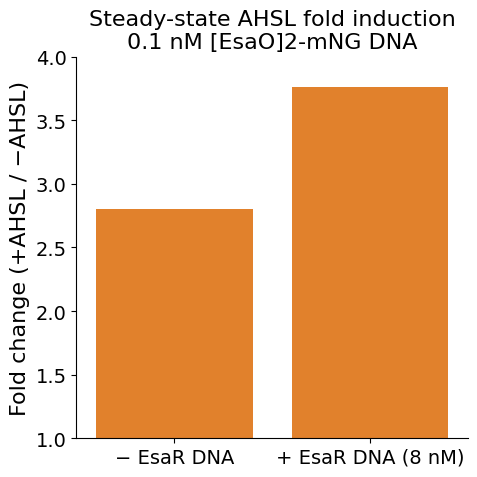

In [ ]:
fold_summary['Condition'] = ['− EsaR DNA', '+ EsaR DNA (8 nM)']

fig, ax = plt.subplots(figsize=(5, 5))

sns.barplot(data=fold_summary, x='Condition', y='Fold_change',
            color='tab:orange', ax=ax)

ax.set(xlabel='', ylabel='Fold change (+AHSL / −AHSL)')
ax.set_title('Steady-state AHSL fold induction\n0.1 nM [EsaO]2-mNG DNA')
ax.set_ylim(1, 4)

sns.despine(fig)
fig.tight_layout()
plt.show()

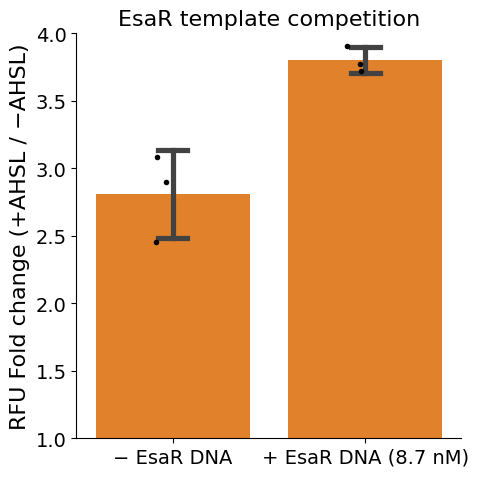

In [ ]:
#| label: mbcn-20261007-fig2


N_LAST_READS = 4   # steady state = mean of each well's last 4 reads

def steady_state_per_well(df, name):
    sub = df[df['Name'] == name].sort_values('Time_hrs')
    return sub.groupby('Well').tail(N_LAST_READS).groupby('Well')['Data'].mean()

def fold_change_wells(df, base_name, ahsl_name, condition):
    base_mean = steady_state_per_well(df, base_name).mean()   # mean of the -AHSL wells
    ahsl = steady_state_per_well(df, ahsl_name)               # one value per +AHSL well
    return pd.DataFrame({'Condition': condition, 'Fold_change': ahsl / base_mean})

fold_no_EsaR = fold_change_wells(
    df_01nM,
    "EsaO-mNG (0.1 nM) - AHSL",
    "EsaO-mNG (0.1 nM) + AHSL",
    '− EsaR DNA',
)

fold_EsaR = fold_change_wells(
    df_01nM_EsaR,
    "EsaO-mNG (0.1 nM) + EsaR (8 nM) - AHSL",
    "EsaO-mNG (0.1 nM) + EsaR (8 nM) + AHSL",
    '+ EsaR DNA (8.7 nM)',   # was '+ EsaR DNA (8 nM)'
)

fold_wells = pd.concat([fold_no_EsaR, fold_EsaR], ignore_index=True)

fig, ax = plt.subplots(figsize=(5, 5))

sns.barplot(data=fold_wells, x='Condition', y='Fold_change', color='tab:orange',
            errorbar='sd', capsize=0.15, ax=ax)
sns.stripplot(data=fold_wells, x='Condition', y='Fold_change', color='black',
              size=4, ax=ax)

ax.set(xlabel='', ylabel='RFU Fold change (+AHSL / −AHSL)')
ax.set_title('EsaR template competition')
ax.set_ylim(1, 4)

sns.despine(fig)
fig.tight_layout()
plt.show()

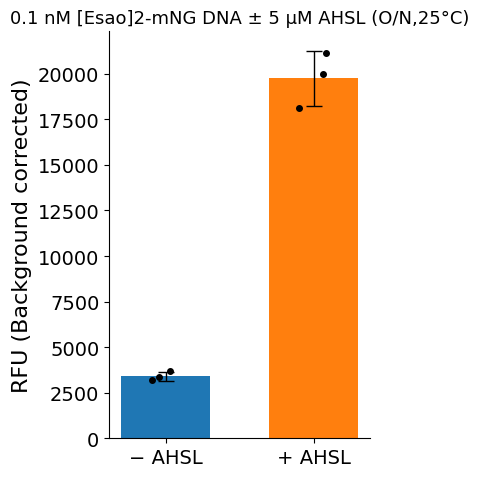

In [ ]:
#| label: mbcn-20261008-fig1

import numpy as np
import matplotlib.pyplot as plt

# Replicate measurements
no_ahsl = np.array([3670, 3370, 3186])
ahsl_5uM = np.array([18149, 19992, 21139])

labels = ["− AHSL", "+ AHSL"]
colors = ["tab:blue", "tab:orange"]   # − AHSL blue, + AHSL orange (as in the other plots)
groups = [no_ahsl, ahsl_5uM]          # renamed from `data` so it can't overwrite your plate reader object
means = [g.mean() for g in groups]
sds = [g.std(ddof=1) for g in groups]   # sample standard deviation

fig, ax = plt.subplots(figsize=(4, 5))
x = np.arange(len(labels))
ax.bar(x, means, yerr=sds, capsize=6, width=0.6, color=colors,
       error_kw={"linewidth": 1})

# Overlay individual replicate points
rng = np.random.default_rng(0)
for i, g in enumerate(groups):
    jitter = rng.uniform(-0.1, 0.1, size=len(g))
    ax.scatter(x[i] + jitter, g, color="black", s=16, zorder=3)

# Compute fold change (+ AHSL relative to − AHSL)
fc = means[1] / means[0]
#print(f"Fold change (+ AHSL / − AHSL): {fc:.2f}")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("RFU (Background corrected)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("0.1 nM [Esao]2-mNG DNA ± 5 µM AHSL (O/N,25°C)", fontsize=13)

plt.tight_layout()
plt.show()

We can see that the standard (here, HPTS) is stable and can be safely used for normalization.

## Normalize Data
Now, use `data.normalize('<standard name>')` to normalize your data. This will calculate the average over a time window at the end of the experiment (by default, 1 hour), then divide all data by the mean of that window-average across all wells with the same `Name` (defined by your platemap).

In [ ]:
# To check the exact name of your standard
platemap = data.platemap
standards = platemap[platemap['Type']=='Standard']
standards['Name'].unique()

array([], dtype=object)

In [ ]:
data = data.normalize('10 uM HPTS')

ValueError: Reference '10 uM HPTS' not found in column 'Name'.

Now replot your curves to see them normalized:

In [ ]:
g = data.plot(style='Type', exclude_types=['Standard'])
# g.savefig('after-normalization.png',dpi=300)

If you want to change the time window over which you calculate the average, you can use the `window` argument:

In [ ]:
# data = data.normalize('10 uM HPTS', window=pd.Timedelta("2.5h"))

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [ ]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

In [ ]:
kinetics.summary

## Visualize Fits

In [ ]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

In [ ]:
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants